In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings("ignore")

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство: {device}")

# Зареждане
df = pd.read_csv(
    "data/traffic_aggregated.csv",
    parse_dates=["datetime"]
)

# Feature Engineering
df["hour"]          = df["datetime"].dt.hour
df["dow"]           = df["datetime"].dt.dayofweek
df["month"]         = df["datetime"].dt.month
df["direction_enc"] = (df["direction"] == "Център").astype(int)
df["hour_sin"]      = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"]      = np.cos(2 * np.pi * df["hour"] / 24)
df["dow_sin"]       = np.sin(2 * np.pi * df["dow"] / 7)
df["dow_cos"]       = np.cos(2 * np.pi * df["dow"] / 7)
df["month_sin"]     = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"]     = np.cos(2 * np.pi * df["month"] / 12)

feature_cols = ["hour_sin", "hour_cos", "dow_sin", "dow_cos",
                "month_sin", "month_cos", "direction_enc"]

# Скалиране
scaler      = StandardScaler()
train_data  = df[df["volume"].notna()].copy().reset_index(drop=True)
X_train     = train_data[feature_cols].values.astype(np.float32)
y_train     = train_data["volume"].values.astype(np.float32).reshape(-1, 1)
y_train_scaled = scaler.fit_transform(y_train)

print(f"Редове         : {len(df):,}")
print(f"Тренировъчни   : {len(train_data):,}")
print(f"Features       : {feature_cols}")
print(f"Volume mean    : {scaler.mean_[0]:.2f}, std: {scaler.scale_[0]:.2f}")

Устройство: cuda
Редове         : 52,608
Тренировъчни   : 35,983
Features       : ['hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'direction_enc']
Volume mean    : 312.51, std: 333.99


In [2]:
print("=" * 60)
print("GAN АРХИТЕКТУРА")
print("=" * 60)

class Generator(nn.Module):
    def __init__(self, noise_dim, condition_dim, hidden_dims):
        super(Generator, self).__init__()
        
        layers = []
        in_dim = noise_dim + condition_dim
        for h_dim in hidden_dims:
            layers.extend([
                nn.Linear(in_dim, h_dim),
                nn.LeakyReLU(0.2),
                nn.BatchNorm1d(h_dim),
                nn.Dropout(0.1)
            ])
            in_dim = h_dim
        layers.append(nn.Linear(hidden_dims[-1], 1))
        self.model = nn.Sequential(*layers)
    
    def forward(self, noise, condition):
        x = torch.cat([noise, condition], dim=1)
        return self.model(x)

class Discriminator(nn.Module):
    def __init__(self, condition_dim, hidden_dims):
        super(Discriminator, self).__init__()
        
        layers = []
        in_dim = 1 + condition_dim
        for h_dim in hidden_dims:
            layers.extend([
                nn.Linear(in_dim, h_dim),
                nn.LeakyReLU(0.2),
                nn.Dropout(0.3)
            ])
            in_dim = h_dim
        layers.append(nn.Linear(hidden_dims[-1], 1))
        layers.append(nn.Sigmoid())
        self.model = nn.Sequential(*layers)
    
    def forward(self, x, condition):
        inp = torch.cat([x, condition], dim=1)
        return self.model(inp)

# Evaluation и helper функции
def evaluate(y_true, y_pred, period_name):
    mask   = ~np.isnan(y_true) & ~np.isnan(y_pred)
    y_true = y_true[mask]
    y_pred = y_pred[mask]
    mae    = mean_absolute_error(y_true, y_pred)
    rmse   = np.sqrt(mean_squared_error(y_true, y_pred))
    return {"period": period_name, "MAE": round(mae, 2), "RMSE": round(rmse, 2)}

def create_test_set(df, start, end):
    mask   = (df["datetime"] >= start) & (df["datetime"] <= end)
    subset = df[mask].copy().reset_index(drop=True)
    subset["volume_true"] = subset["volume"]
    subset["volume"]      = np.nan
    return subset

test_periods = {
    "short_1" : ("2023-06-05", "2023-06-07"),
    "short_2" : ("2023-11-05", "2023-11-07"),
    "short_3" : ("2023-12-05", "2023-12-07"),
    "medium_1": ("2023-06-05", "2023-06-18"),
    "medium_2": ("2023-11-05", "2023-11-18"),
    "medium_3": ("2023-12-05", "2023-12-18"),
    "long_1"  : ("2023-06-01", "2023-06-30"),
    "long_2"  : ("2023-11-01", "2023-11-30"),
    "long_3"  : ("2023-12-01", "2023-12-31"),
}

def train_gan(X_train, y_train_scaled, config, verbose=False):
    """Обучава Conditional GAN."""
    
    # Dataset
    X_tensor = torch.FloatTensor(X_train).to(device)
    y_tensor = torch.FloatTensor(y_train_scaled).to(device)
    dataset  = TensorDataset(y_tensor, X_tensor)
    loader   = DataLoader(dataset, batch_size=config["batch_size"], shuffle=True)
    
    # Модели
    G = Generator(
        noise_dim     = config["noise_dim"],
        condition_dim = len(feature_cols),
        hidden_dims   = config["g_hidden"]
    ).to(device)
    
    D = Discriminator(
        condition_dim = len(feature_cols),
        hidden_dims   = config["d_hidden"]
    ).to(device)
    
    # Оптимизатори
    opt_G = optim.Adam(G.parameters(), lr=config["lr_g"], betas=(0.5, 0.999))
    opt_D = optim.Adam(D.parameters(), lr=config["lr_d"], betas=(0.5, 0.999))
    
    criterion = nn.BCELoss()
    
    g_losses = []
    d_losses = []
    
    for epoch in range(config["epochs"]):
        g_epoch_loss = 0
        d_epoch_loss = 0
        
        for y_real, x_cond in loader:
            batch_size = y_real.size(0)
            real_labels = torch.ones(batch_size, 1).to(device)
            fake_labels = torch.zeros(batch_size, 1).to(device)
            
            # Обучение на Discriminator
            opt_D.zero_grad()
            d_real = D(y_real, x_cond)
            d_real_loss = criterion(d_real, real_labels)
            
            noise  = torch.randn(batch_size, config["noise_dim"]).to(device)
            y_fake = G(noise, x_cond)
            d_fake = D(y_fake.detach(), x_cond)
            d_fake_loss = criterion(d_fake, fake_labels)
            
            d_loss = (d_real_loss + d_fake_loss) / 2
            d_loss.backward()
            opt_D.step()
            
            # Обучение на Generator
            opt_G.zero_grad()
            noise  = torch.randn(batch_size, config["noise_dim"]).to(device)
            y_fake = G(noise, x_cond)
            d_fake = D(y_fake, x_cond)
            g_loss = criterion(d_fake, real_labels)
            g_loss.backward()
            opt_G.step()
            
            g_epoch_loss += g_loss.item()
            d_epoch_loss += d_loss.item()
        
        g_losses.append(g_epoch_loss / len(loader))
        d_losses.append(d_epoch_loss / len(loader))
        
        if verbose and (epoch + 1) % 20 == 0:
            print(f"  Epoch {epoch+1:>3}: G_loss={g_losses[-1]:.4f}, D_loss={d_losses[-1]:.4f}")
    
    return G, D, g_losses, d_losses

def gan_impute(G, scaler, test_df, feature_cols, noise_dim, n_samples=50):
    """
    Импутира с GAN — генерираме n_samples и вземаме средната стойност
    за по-стабилни предсказвания.
    """
    G.eval()
    with torch.no_grad():
        X_test = torch.FloatTensor(
            test_df[feature_cols].values.astype(np.float32)
        ).to(device)
        
        # Генерираме множество проби и усредняваме
        samples = []
        for _ in range(n_samples):
            noise  = torch.randn(len(X_test), noise_dim).to(device)
            output = G(noise, X_test)
            samples.append(output.cpu().numpy())
        
        mean_output = np.mean(samples, axis=0)
        imputed     = scaler.inverse_transform(mean_output)
        imputed     = np.maximum(imputed, 0)
    
    return imputed.flatten()

# Тест на архитектурата
test_G = Generator(noise_dim=32, condition_dim=len(feature_cols), 
                   hidden_dims=[256, 128, 64]).to(device)
test_D = Discriminator(condition_dim=len(feature_cols),
                       hidden_dims=[256, 128, 64]).to(device)

print(f"Generator параметри    : {sum(p.numel() for p in test_G.parameters()):,}")
print(f"Discriminator параметри: {sum(p.numel() for p in test_D.parameters()):,}")
print(f"\nGenerator архитектура:")
print(test_G)

GAN АРХИТЕКТУРА
Generator параметри    : 52,353
Discriminator параметри: 43,521

Generator архитектура:
Generator(
  (model): Sequential(
    (0): Linear(in_features=39, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Dropout(p=0.1, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): Dropout(p=0.1, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): LeakyReLU(negative_slope=0.2)
    (10): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): Dropout(p=0.1, inplace=False)
    (12): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [3]:
print("=" * 60)
print("GAN — HYPERPARAMETER TUNING")
print("=" * 60)

configs = [
    {"noise_dim": 32,  "g_hidden": [256, 128, 64], "d_hidden": [256, 128, 64], "lr_g": 0.0002, "lr_d": 0.0002, "batch_size": 64,  "epochs": 100},
    {"noise_dim": 64,  "g_hidden": [256, 128, 64], "d_hidden": [256, 128, 64], "lr_g": 0.0002, "lr_d": 0.0002, "batch_size": 64,  "epochs": 100},
    {"noise_dim": 32,  "g_hidden": [512, 256, 128], "d_hidden": [512, 256, 128], "lr_g": 0.0002, "lr_d": 0.0002, "batch_size": 64,  "epochs": 100},
    {"noise_dim": 32,  "g_hidden": [256, 128, 64], "d_hidden": [256, 128, 64], "lr_g": 0.0002, "lr_d": 0.0001, "batch_size": 64,  "epochs": 100},
    {"noise_dim": 32,  "g_hidden": [256, 128, 64], "d_hidden": [256, 128, 64], "lr_g": 0.0002, "lr_d": 0.0002, "batch_size": 128, "epochs": 100},
    {"noise_dim": 32,  "g_hidden": [256, 128, 64], "d_hidden": [256, 128, 64], "lr_g": 0.0002, "lr_d": 0.0002, "batch_size": 64,  "epochs": 200},
]

tuning_results = []

for i, config in enumerate(configs):
    print(f"\nКонфигурация {i+1}/{len(configs)}: "
          f"noise={config['noise_dim']}, "
          f"g_hidden={config['g_hidden']}, "
          f"lr_g={config['lr_g']}, lr_d={config['lr_d']}, "
          f"batch={config['batch_size']}, epochs={config['epochs']}")
    
    G, D, g_losses, d_losses = train_gan(X_train, y_train_scaled, config, verbose=True)
    
    period_scores = []
    for name, (start, end) in test_periods.items():
        test    = create_test_set(df, start, end)
        imputed = gan_impute(G, scaler, test, feature_cols, config["noise_dim"])
        score   = evaluate(
            test["volume_true"].values,
            imputed,
            name
        )
        score["category"] = name.split("_")[0]
        period_scores.append(score)
    
    scores_df = pd.DataFrame(period_scores)
    avg_mae   = scores_df["MAE"].mean()
    avg_rmse  = scores_df["RMSE"].mean()
    
    tuning_results.append({
        "config_id"  : i + 1,
        "noise_dim"  : config["noise_dim"],
        "g_hidden"   : str(config["g_hidden"]),
        "lr_g"       : config["lr_g"],
        "lr_d"       : config["lr_d"],
        "batch_size" : config["batch_size"],
        "epochs"     : config["epochs"],
        "MAE_mean"   : round(avg_mae, 2),
        "RMSE_mean"  : round(avg_rmse, 2),
        "final_g_loss": round(g_losses[-1], 4),
        "final_d_loss": round(d_losses[-1], 4)
    })
    
    print(f"  → Avg MAE={avg_mae:.2f}, Avg RMSE={avg_rmse:.2f}, "
          f"G_loss={g_losses[-1]:.4f}, D_loss={d_losses[-1]:.4f}")

tuning_df = pd.DataFrame(tuning_results)
print(f"\n{'='*60}")
print(f"РЕЗУЛТАТИ ОТ TUNING:")
print(tuning_df.to_string(index=False))

best_idx = tuning_df["MAE_mean"].idxmin()
print(f"\nНай-добра конфигурация: #{tuning_df.loc[best_idx, 'config_id']}")
print(f"  MAE  : {tuning_df.loc[best_idx, 'MAE_mean']}")
print(f"  RMSE : {tuning_df.loc[best_idx, 'RMSE_mean']}")

GAN — HYPERPARAMETER TUNING

Конфигурация 1/6: noise=32, g_hidden=[256, 128, 64], lr_g=0.0002, lr_d=0.0002, batch=64, epochs=100
  Epoch  20: G_loss=0.7170, D_loss=0.6858
  Epoch  40: G_loss=0.7196, D_loss=0.6855
  Epoch  60: G_loss=0.7258, D_loss=0.6832
  Epoch  80: G_loss=0.7362, D_loss=0.6788
  Epoch 100: G_loss=0.7467, D_loss=0.6777
  → Avg MAE=147.44, Avg RMSE=190.89, G_loss=0.7467, D_loss=0.6777

Конфигурация 2/6: noise=64, g_hidden=[256, 128, 64], lr_g=0.0002, lr_d=0.0002, batch=64, epochs=100
  Epoch  20: G_loss=0.7404, D_loss=0.6785
  Epoch  40: G_loss=0.7413, D_loss=0.6792
  Epoch  60: G_loss=0.7594, D_loss=0.6732
  Epoch  80: G_loss=0.7731, D_loss=0.6692
  Epoch 100: G_loss=0.7793, D_loss=0.6670
  → Avg MAE=189.15, Avg RMSE=239.41, G_loss=0.7793, D_loss=0.6670

Конфигурация 3/6: noise=32, g_hidden=[512, 256, 128], lr_g=0.0002, lr_d=0.0002, batch=64, epochs=100
  Epoch  20: G_loss=0.7447, D_loss=0.6777
  Epoch  40: G_loss=0.7563, D_loss=0.6751
  Epoch  60: G_loss=0.7692, D_lo

In [4]:
print("=" * 60)
print("GAN — РАЗШИРЕНО ТЪРСЕНЕ")
print("=" * 60)

extended_configs = [
    {"noise_dim": 32, "g_hidden": [256, 128, 64], "d_hidden": [256, 128, 64], "lr_g": 0.0002, "lr_d": 0.0001, "batch_size": 64,  "epochs": 200},
    {"noise_dim": 32, "g_hidden": [256, 128, 64], "d_hidden": [256, 128, 64], "lr_g": 0.0002, "lr_d": 0.0001, "batch_size": 32,  "epochs": 100},
    {"noise_dim": 32, "g_hidden": [512, 256, 128], "d_hidden": [256, 128, 64], "lr_g": 0.0002, "lr_d": 0.0001, "batch_size": 64, "epochs": 100},
    {"noise_dim": 16, "g_hidden": [256, 128, 64], "d_hidden": [256, 128, 64], "lr_g": 0.0002, "lr_d": 0.0001, "batch_size": 64,  "epochs": 100},
    {"noise_dim": 32, "g_hidden": [256, 128, 64], "d_hidden": [128, 64],      "lr_g": 0.0002, "lr_d": 0.0001, "batch_size": 64,  "epochs": 100},
]

extended_results = []

for i, config in enumerate(extended_configs):
    print(f"\nКонфигурация {i+1}/{len(extended_configs)}: "
          f"noise={config['noise_dim']}, "
          f"g_hidden={config['g_hidden']}, "
          f"d_hidden={config['d_hidden']}, "
          f"lr_g={config['lr_g']}, lr_d={config['lr_d']}, "
          f"batch={config['batch_size']}, epochs={config['epochs']}")
    
    G, D, g_losses, d_losses = train_gan(X_train, y_train_scaled, config, verbose=True)
    
    period_scores = []
    for name, (start, end) in test_periods.items():
        test    = create_test_set(df, start, end)
        imputed = gan_impute(G, scaler, test, feature_cols, config["noise_dim"])
        score   = evaluate(
            test["volume_true"].values,
            imputed,
            name
        )
        score["category"] = name.split("_")[0]
        period_scores.append(score)
    
    scores_df = pd.DataFrame(period_scores)
    avg_mae   = scores_df["MAE"].mean()
    avg_rmse  = scores_df["RMSE"].mean()
    
    extended_results.append({
        "noise_dim"   : config["noise_dim"],
        "g_hidden"    : str(config["g_hidden"]),
        "d_hidden"    : str(config["d_hidden"]),
        "lr_g"        : config["lr_g"],
        "lr_d"        : config["lr_d"],
        "batch_size"  : config["batch_size"],
        "epochs"      : config["epochs"],
        "MAE_mean"    : round(avg_mae, 2),
        "RMSE_mean"   : round(avg_rmse, 2),
        "final_g_loss": round(g_losses[-1], 4),
        "final_d_loss": round(d_losses[-1], 4)
    })
    
    print(f"  → Avg MAE={avg_mae:.2f}, Avg RMSE={avg_rmse:.2f}, "
          f"G_loss={g_losses[-1]:.4f}, D_loss={d_losses[-1]:.4f}")

extended_df = pd.DataFrame(extended_results)
print(f"\nРезултати:")
print(extended_df.to_string(index=False))

best_idx = extended_df["MAE_mean"].idxmin()
print(f"\nНай-добра конфигурация:")
print(extended_df.loc[best_idx].to_string())

GAN — РАЗШИРЕНО ТЪРСЕНЕ

Конфигурация 1/5: noise=32, g_hidden=[256, 128, 64], d_hidden=[256, 128, 64], lr_g=0.0002, lr_d=0.0001, batch=64, epochs=200
  Epoch  20: G_loss=0.6992, D_loss=0.6911
  Epoch  40: G_loss=0.7016, D_loss=0.6909
  Epoch  60: G_loss=0.7018, D_loss=0.6905
  Epoch  80: G_loss=0.7012, D_loss=0.6901
  Epoch 100: G_loss=0.7047, D_loss=0.6898
  Epoch 120: G_loss=0.7074, D_loss=0.6888
  Epoch 140: G_loss=0.7090, D_loss=0.6877
  Epoch 160: G_loss=0.7151, D_loss=0.6870
  Epoch 180: G_loss=0.7157, D_loss=0.6849
  Epoch 200: G_loss=0.7218, D_loss=0.6830
  → Avg MAE=145.22, Avg RMSE=181.97, G_loss=0.7218, D_loss=0.6830

Конфигурация 2/5: noise=32, g_hidden=[256, 128, 64], d_hidden=[256, 128, 64], lr_g=0.0002, lr_d=0.0001, batch=32, epochs=100
  Epoch  20: G_loss=0.7045, D_loss=0.6887
  Epoch  40: G_loss=0.7110, D_loss=0.6868
  Epoch  60: G_loss=0.7221, D_loss=0.6847
  Epoch  80: G_loss=0.7336, D_loss=0.6793
  Epoch 100: G_loss=0.7456, D_loss=0.6763
  → Avg MAE=151.20, Avg RMSE

In [5]:
print("=" * 60)
print("GAN — ФИНАЛНО ТЪРСЕНЕ")
print("=" * 60)

final_configs = [
    {"noise_dim": 32, "g_hidden": [256, 128, 64], "d_hidden": [128, 64], "lr_g": 0.0002, "lr_d": 0.0001, "batch_size": 64,  "epochs": 200},
    {"noise_dim": 32, "g_hidden": [256, 128, 64], "d_hidden": [128, 64], "lr_g": 0.0002, "lr_d": 0.0001, "batch_size": 64,  "epochs": 300},
    {"noise_dim": 16, "g_hidden": [256, 128, 64], "d_hidden": [128, 64], "lr_g": 0.0002, "lr_d": 0.0001, "batch_size": 64,  "epochs": 100},
    {"noise_dim": 32, "g_hidden": [512, 256, 128], "d_hidden": [128, 64], "lr_g": 0.0002, "lr_d": 0.0001, "batch_size": 64, "epochs": 100},
    {"noise_dim": 32, "g_hidden": [256, 128, 64], "d_hidden": [64, 32],  "lr_g": 0.0002, "lr_d": 0.0001, "batch_size": 64,  "epochs": 100},
]

final_results = []

for i, config in enumerate(final_configs):
    print(f"\nКонфигурация {i+1}/{len(final_configs)}: "
          f"noise={config['noise_dim']}, "
          f"g={config['g_hidden']}, "
          f"d={config['d_hidden']}, "
          f"epochs={config['epochs']}")
    
    G, D, g_losses, d_losses = train_gan(X_train, y_train_scaled, config, verbose=True)
    
    period_scores = []
    for name, (start, end) in test_periods.items():
        test    = create_test_set(df, start, end)
        imputed = gan_impute(G, scaler, test, feature_cols, config["noise_dim"])
        score   = evaluate(
            test["volume_true"].values,
            imputed,
            name
        )
        score["category"] = name.split("_")[0]
        period_scores.append(score)
    
    scores_df = pd.DataFrame(period_scores)
    avg_mae   = scores_df["MAE"].mean()
    avg_rmse  = scores_df["RMSE"].mean()
    
    final_results.append({
        "noise_dim"   : config["noise_dim"],
        "g_hidden"    : str(config["g_hidden"]),
        "d_hidden"    : str(config["d_hidden"]),
        "epochs"      : config["epochs"],
        "MAE_mean"    : round(avg_mae, 2),
        "RMSE_mean"   : round(avg_rmse, 2),
        "final_g_loss": round(g_losses[-1], 4),
        "final_d_loss": round(d_losses[-1], 4)
    })
    
    print(f"  → Avg MAE={avg_mae:.2f}, Avg RMSE={avg_rmse:.2f}, "
          f"G_loss={g_losses[-1]:.4f}, D_loss={d_losses[-1]:.4f}")

final_df = pd.DataFrame(final_results)
print(f"\nРезултати:")
print(final_df.to_string(index=False))

best_idx = final_df["MAE_mean"].idxmin()
print(f"\nНай-добра конфигурация:")
print(final_df.loc[best_idx].to_string())

GAN — ФИНАЛНО ТЪРСЕНЕ

Конфигурация 1/5: noise=32, g=[256, 128, 64], d=[128, 64], epochs=200
  Epoch  20: G_loss=0.6940, D_loss=0.6926
  Epoch  40: G_loss=0.6942, D_loss=0.6930
  Epoch  60: G_loss=0.6941, D_loss=0.6930
  Epoch  80: G_loss=0.6938, D_loss=0.6930
  Epoch 100: G_loss=0.6939, D_loss=0.6929
  Epoch 120: G_loss=0.6938, D_loss=0.6931
  Epoch 140: G_loss=0.6940, D_loss=0.6929
  Epoch 160: G_loss=0.6937, D_loss=0.6930
  Epoch 180: G_loss=0.6939, D_loss=0.6929
  Epoch 200: G_loss=0.6943, D_loss=0.6929
  → Avg MAE=139.72, Avg RMSE=178.54, G_loss=0.6943, D_loss=0.6929

Конфигурация 2/5: noise=32, g=[256, 128, 64], d=[128, 64], epochs=300
  Epoch  20: G_loss=0.6944, D_loss=0.6928
  Epoch  40: G_loss=0.6946, D_loss=0.6931
  Epoch  60: G_loss=0.6941, D_loss=0.6929
  Epoch  80: G_loss=0.6938, D_loss=0.6930
  Epoch 100: G_loss=0.6938, D_loss=0.6930
  Epoch 120: G_loss=0.6938, D_loss=0.6929
  Epoch 140: G_loss=0.6941, D_loss=0.6930
  Epoch 160: G_loss=0.6943, D_loss=0.6929
  Epoch 180: G

In [6]:
print("=" * 60)
print("GAN — ПОСЛЕДЕН КРЪГ")
print("=" * 60)

last_configs = [
    {"noise_dim": 32, "g_hidden": [256, 128, 64], "d_hidden": [128, 64], "lr_g": 0.0002, "lr_d": 0.0001, "batch_size": 64, "epochs": 400},
    {"noise_dim": 32, "g_hidden": [256, 128, 64], "d_hidden": [128, 64], "lr_g": 0.0002, "lr_d": 0.0001, "batch_size": 64, "epochs": 500},
    {"noise_dim": 32, "g_hidden": [512, 256, 128], "d_hidden": [128, 64], "lr_g": 0.0002, "lr_d": 0.0001, "batch_size": 64, "epochs": 300},
]

last_results = []

for i, config in enumerate(last_configs):
    print(f"\nКонфигурация {i+1}/{len(last_configs)}: "
          f"g={config['g_hidden']}, d={config['d_hidden']}, "
          f"epochs={config['epochs']}")
    
    G, D, g_losses, d_losses = train_gan(X_train, y_train_scaled, config, verbose=True)
    
    period_scores = []
    for name, (start, end) in test_periods.items():
        test    = create_test_set(df, start, end)
        imputed = gan_impute(G, scaler, test, feature_cols, config["noise_dim"])
        score   = evaluate(
            test["volume_true"].values,
            imputed,
            name
        )
        score["category"] = name.split("_")[0]
        period_scores.append(score)
    
    scores_df = pd.DataFrame(period_scores)
    avg_mae   = scores_df["MAE"].mean()
    avg_rmse  = scores_df["RMSE"].mean()
    
    last_results.append({
        "g_hidden"    : str(config["g_hidden"]),
        "d_hidden"    : str(config["d_hidden"]),
        "epochs"      : config["epochs"],
        "MAE_mean"    : round(avg_mae, 2),
        "RMSE_mean"   : round(avg_rmse, 2),
        "final_g_loss": round(g_losses[-1], 4),
        "final_d_loss": round(d_losses[-1], 4)
    })
    
    print(f"  → Avg MAE={avg_mae:.2f}, Avg RMSE={avg_rmse:.2f}, "
          f"G_loss={g_losses[-1]:.4f}, D_loss={d_losses[-1]:.4f}")

last_df = pd.DataFrame(last_results)
print(f"\nРезултати:")
print(last_df.to_string(index=False))

GAN — ПОСЛЕДЕН КРЪГ

Конфигурация 1/3: g=[256, 128, 64], d=[128, 64], epochs=400
  Epoch  20: G_loss=0.6949, D_loss=0.6924
  Epoch  40: G_loss=0.6943, D_loss=0.6930
  Epoch  60: G_loss=0.6944, D_loss=0.6930
  Epoch  80: G_loss=0.6946, D_loss=0.6927
  Epoch 100: G_loss=0.6942, D_loss=0.6928
  Epoch 120: G_loss=0.6943, D_loss=0.6929
  Epoch 140: G_loss=0.6940, D_loss=0.6927
  Epoch 160: G_loss=0.6943, D_loss=0.6927
  Epoch 180: G_loss=0.6951, D_loss=0.6924
  Epoch 200: G_loss=0.6947, D_loss=0.6928
  Epoch 220: G_loss=0.6949, D_loss=0.6925
  Epoch 240: G_loss=0.6946, D_loss=0.6925
  Epoch 260: G_loss=0.6946, D_loss=0.6925
  Epoch 280: G_loss=0.6954, D_loss=0.6925
  Epoch 300: G_loss=0.6948, D_loss=0.6928
  Epoch 320: G_loss=0.6953, D_loss=0.6924
  Epoch 340: G_loss=0.6953, D_loss=0.6924
  Epoch 360: G_loss=0.6953, D_loss=0.6923
  Epoch 380: G_loss=0.6952, D_loss=0.6924
  Epoch 400: G_loss=0.6953, D_loss=0.6925
  → Avg MAE=116.43, Avg RMSE=149.62, G_loss=0.6953, D_loss=0.6925

Конфигурация

GAN — ФИНАЛНИ РЕЗУЛТАТИ
Финална конфигурация: {'noise_dim': 32, 'g_hidden': [256, 128, 64], 'd_hidden': [128, 64], 'lr_g': 0.0002, 'lr_d': 0.0001, 'batch_size': 64, 'epochs': 400}
  Epoch  20: G_loss=0.6947, D_loss=0.6927
  Epoch  40: G_loss=0.6946, D_loss=0.6928
  Epoch  60: G_loss=0.6936, D_loss=0.6930
  Epoch  80: G_loss=0.6942, D_loss=0.6929
  Epoch 100: G_loss=0.6940, D_loss=0.6929
  Epoch 120: G_loss=0.6942, D_loss=0.6929
  Epoch 140: G_loss=0.6940, D_loss=0.6929
  Epoch 160: G_loss=0.6944, D_loss=0.6929
  Epoch 180: G_loss=0.6943, D_loss=0.6928
  Epoch 200: G_loss=0.6941, D_loss=0.6927
  Epoch 220: G_loss=0.6944, D_loss=0.6927
  Epoch 240: G_loss=0.6945, D_loss=0.6926
  Epoch 260: G_loss=0.6945, D_loss=0.6927
  Epoch 280: G_loss=0.6946, D_loss=0.6927
  Epoch 300: G_loss=0.6949, D_loss=0.6921
  Epoch 320: G_loss=0.6948, D_loss=0.6923
  Epoch 340: G_loss=0.6946, D_loss=0.6924
  Epoch 360: G_loss=0.6950, D_loss=0.6923
  Epoch 380: G_loss=0.6957, D_loss=0.6925
  Epoch 400: G_loss=0.

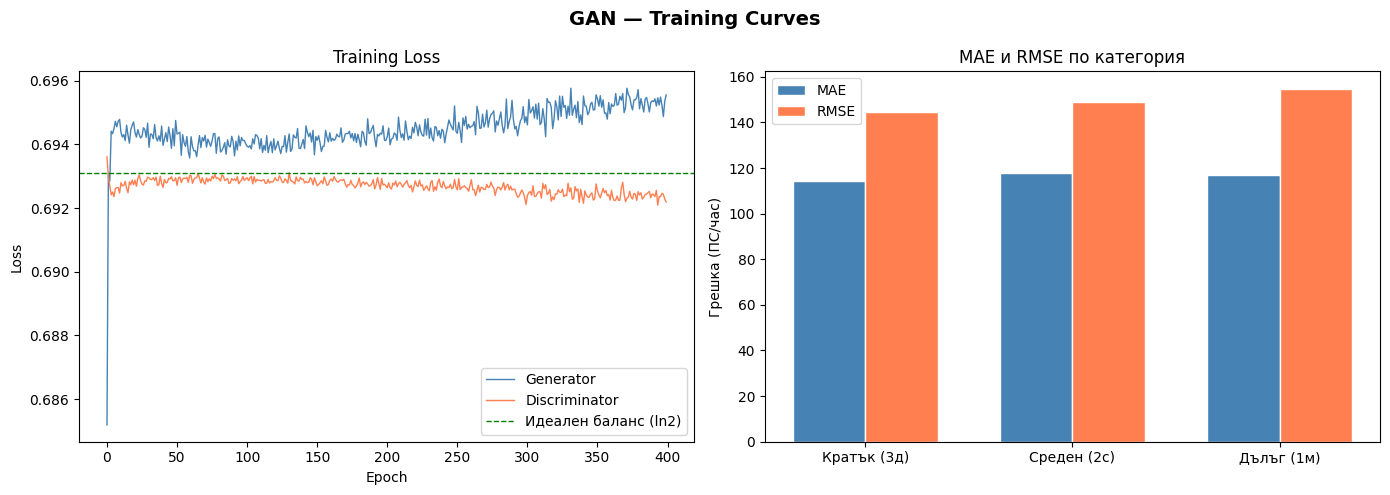

In [7]:
print("=" * 60)
print("GAN — ФИНАЛНИ РЕЗУЛТАТИ")
print("=" * 60)

best_gan_config = {
    "noise_dim" : 32,
    "g_hidden"  : [256, 128, 64],
    "d_hidden"  : [128, 64],
    "lr_g"      : 0.0002,
    "lr_d"      : 0.0001,
    "batch_size": 64,
    "epochs"    : 400
}

print(f"Финална конфигурация: {best_gan_config}")

# Обучаваме финалния модел
final_G, final_D, g_losses, d_losses = train_gan(
    X_train, y_train_scaled, best_gan_config, verbose=True
)

# Оценяваме по всички тестови периоди
results_gan = []
for name, (start, end) in test_periods.items():
    test    = create_test_set(df, start, end)
    imputed = gan_impute(final_G, scaler, test, feature_cols, 
                         best_gan_config["noise_dim"])
    score   = evaluate(
        test["volume_true"].values,
        imputed,
        name
    )
    score["category"] = name.split("_")[0]
    results_gan.append(score)

results_gan_df = pd.DataFrame(results_gan)
print(f"\nФинални резултати GAN:")
print(results_gan_df.to_string(index=False))
print(f"\nСредно по категория:")
print(results_gan_df.groupby("category")[["MAE","RMSE"]]
      .mean().round(2).to_string())

# Запазване
results_gan_df.to_csv("data/results_gan.csv", index=False)
print(f"\nЗапазено в data/results_gan.csv")

# Визуализация на training curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("GAN — Training Curves", fontsize=14, fontweight="bold")

ax1.plot(g_losses, color="steelblue", linewidth=1, label="Generator")
ax1.plot(d_losses, color="coral", linewidth=1, label="Discriminator")
ax1.axhline(y=0.6931, color="green", linestyle="--", 
            linewidth=1, label="Идеален баланс (ln2)")
ax1.set_title("Training Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()

# MAE по тестови периоди
categories = ["short", "medium", "long"]
x     = np.arange(len(categories))
width = 0.35

gan_mae  = [results_gan_df[results_gan_df["category"]==c]["MAE"].mean() for c in categories]
gan_rmse = [results_gan_df[results_gan_df["category"]==c]["RMSE"].mean() for c in categories]

ax2.bar(x - width/2, gan_mae,  width, label="MAE",  color="steelblue", edgecolor="white")
ax2.bar(x + width/2, gan_rmse, width, label="RMSE", color="coral",     edgecolor="white")
ax2.set_title("MAE и RMSE по категория")
ax2.set_xticks(x)
ax2.set_xticklabels(["Кратък (3д)", "Среден (2с)", "Дълъг (1м)"])
ax2.set_ylabel("Грешка (ПС/час)")
ax2.legend()

plt.tight_layout()
plt.savefig("gan_results.png", dpi=150, bbox_inches="tight")
plt.show()